# 04 · Expression — EMT-transcription-factor axis along the trajectory

*(Renumbered from 06: with Gate 2 = GO / Gate 3 = NA the manifold is non-branching, so the
branching-only correlation (04) and modules (05) notebooks are **not** produced; the unconditional
EMT-TF step becomes 04.)*

Score a broadened EMT-TF panel (Snail/Zeb/Twist + FOXC/PRRX families) gated on detectable expression,
derive the two most pseudotime-informative distinct factors, and overlay thresholded expressers
categorically on the grey manifold. Deliverable: `expression.pdf`.

In [1]:
import os, sys, glob, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import scipy.sparse as sp
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
raw_name = 'Data_' + name.replace('-2','')
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', raw_name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Caron2020_Hematologic-2 | category: Hematologic


In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 25784 | pseudotime range 0.0 -> 10.66


### Derive the end-specific EMT-TFs (data-driven)
For each candidate TF: fraction expressing, mean expression in the early (root) vs late (terminus)
pseudotime tercile, and Spearman rho vs pseudotime. Keep only detectably-expressed factors
(frac_expr > 0.01), then take the two most distinct by pseudotime ordering.

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; rho,p = spearmanr(tn, x)
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
FLOOR = 0.01
ok = df[df.frac_expr > FLOOR].sort_values('rho_vs_t')
print(f'\ndetectably-expressed EMT-TFs (frac_expr > {FLOOR}):', list(ok.TF))
early_tf = ok.iloc[0]['TF']
rest = ok[ok.TF != early_tf]
late_tf = rest.iloc[-1]['TF'] if len(rest) else ok.iloc[-1]['TF']
print(f'derived pair: {early_tf} (early/root end) <-> {late_tf} (late/terminus end)')

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
  ZEB2      0.406       0.425      0.307    -0.063    EARLY(root)
 SNAI2      0.000       0.000      0.000    -0.007 LATE(terminus)
 FOXC2      0.001       0.001      0.000    -0.004    EARLY(root)
TWIST1      0.000       0.000      0.000     0.008 LATE(terminus)
 SNAI1      0.068       0.042      0.040     0.053    EARLY(root)
  ZEB1      0.089       0.047      0.061     0.096 LATE(terminus)

detectably-expressed EMT-TFs (frac_expr > 0.01): ['ZEB2', 'SNAI1', 'ZEB1']
derived pair: ZEB2 (early/root end) <-> ZEB1 (late/terminus end)


### EMT-TF expression overlay (deliverable)
House style - `figsize=(3.5,1.5)`, pseudotime left->right, `size=30`. **Categorical** overlay of
thresholded expressers (upper quartile of positive cells) on the grey manifold - not a continuous
colormap.

ZEB2: 40.6% expressing; 2617 shown (upper quartile), mean pseudotime of shown = 0.26
ZEB1: 8.9% expressing; 573 shown (upper quartile), mean pseudotime of shown = 0.31
EMT-TFs shown: ZEB2 + ZEB1 | saved expression.pdf


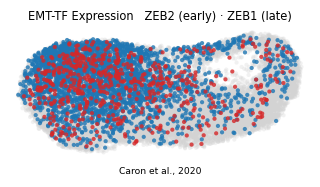

In [5]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X; return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (early) · {late_tf} (late)', size=7.5)
ax.text(.5,-.14,'Caron et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
plt.show()
for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), mean pseudotime of shown = {tn[m].mean():.2f}')
print('EMT-TFs shown:', early_tf, '+', late_tf, '| saved expression.pdf')